Necesitas subir el archivo datos_2022.xlsx y copiar su ruta dando click derecho copiar ruta, pegar en el codigo en la parte donde acarga el archivo.

Dropdown(description='Estación:', index=9, options=('Aguilas', 'Atemajac', 'Centro', 'Las Pintas', 'Loma Dorad…

Datos filtrados para la estación: Vallarta
       Estacion           Date_Time TMPI
78840  Vallarta 2023-01-01 00:00:00   24
78841  Vallarta 2023-01-01 01:00:00   24
78842  Vallarta 2023-01-01 02:00:00   24
78843  Vallarta 2023-01-01 03:00:00   24
78844  Vallarta 2023-01-01 04:00:00   24
Datos después del preprocesamiento para la estación: Vallarta
       Estacion           Date_Time  TMPI
78840  Vallarta 2023-01-01 00:00:00  24.0
78841  Vallarta 2023-01-01 01:00:00  24.0
78842  Vallarta 2023-01-01 02:00:00  24.0
78843  Vallarta 2023-01-01 03:00:00  24.0
78844  Vallarta 2023-01-01 04:00:00  24.0


<ipython-input-5-2650303813>:51: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_filtrada['Date_Time'] = pd.to_datetime(data_filtrada['Date_Time'])


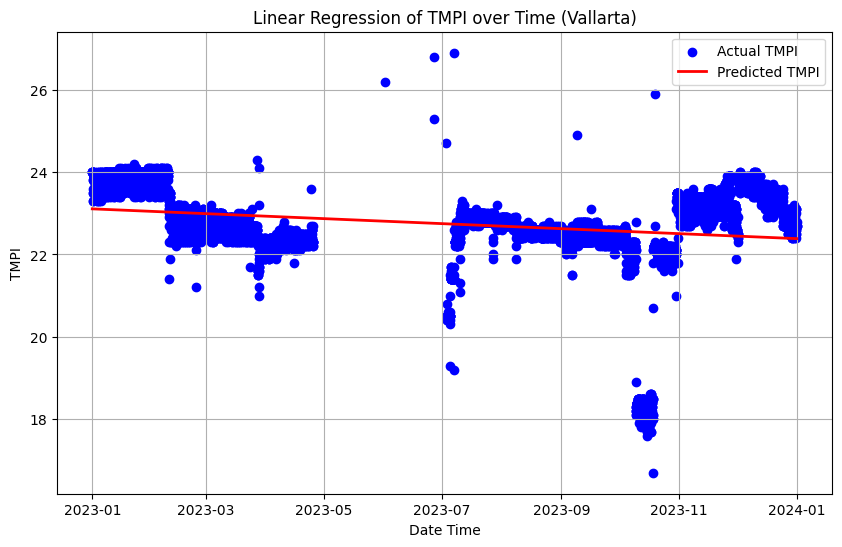


    Esta gráfica muestra los resultados del modelo de regresión lineal aplicado a los datos de TMPI para la estación Vallarta.
    - Los puntos azules representan los valores reales de TMPI a lo largo del tiempo.
    - La línea roja representa los valores predichos por el modelo de regresión lineal.
    Observamos cómo el modelo lineal intenta ajustar una línea recta a los datos de TMPI, lo que puede ayudar a identificar tendencias generales.
    


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


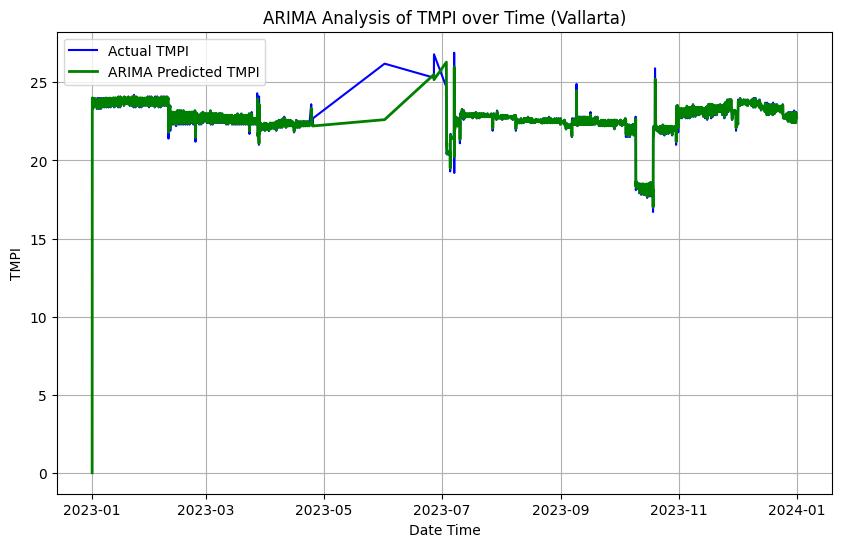


    Esta gráfica muestra los resultados del modelo ARIMA aplicado a los datos de TMPI para la estación Vallarta.
    - La línea azul representa los valores reales de TMPI a lo largo del tiempo.
    - La línea verde representa los valores predichos por el modelo ARIMA.
    Observamos cómo el modelo ARIMA sigue más de cerca los cambios en los datos de TMPI en comparación con el modelo de regresión lineal, capturando tanto las tendencias como las fluctuaciones.
    


In [5]:
# -*- coding: utf-8 -*-
"""
### Parte 1: Análisis de TMPI
#### Autor: [Guillero García Torales]
#### Objetivo: Demostración de predicción de TMPI utilizando modelos de regresión lineal y ARIMA
"""

# Importar las librerías necesarias
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from IPython.display import display, clear_output
from ipywidgets import widgets

# Cargar el archivo de datos (Asegúrate de cargar el archivo  en el entorno de Colab)
file_path = '/content/datos_2023.xlsx'  # Reemplaza con la ruta a tu archivo en Google Colab
sheet_name = 'base datos 2023'          #remplaza el nombre con el de la hoja de tu archivo

# Leer el archivo de Excel
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Mostrar las primeras filas del DataFrame
print(df.head())

# Extraer las columnas necesarias
#Asegúrate de que tu arhivo tenga estos nombres en sus columnas, sin espacio, acentos, etc...
data = df[['Estacion', 'Date_Time', 'TMPI']]

# Crear un menú desplegable para seleccionar la estación
estaciones = data['Estacion'].unique()
estacion_selector = widgets.Dropdown(
    options=estaciones,
    description='Estación:',
    disabled=False,
)
display(estacion_selector)

# Función para actualizar la gráfica y el análisis basado en la estación seleccionada
def analizar_estacion(estacion):
    # Limpiar la salida anterior
    clear_output(wait=True)
    display(estacion_selector)

    # Filtrar las filas donde la 'Estacion' es la seleccionada
    data_filtrada = data[data['Estacion'] == estacion]

    print(f"Datos filtrados para la estación: {estacion}")
    print(data_filtrada.head())

    # Convertir 'Date_Time' a formato datetime
    data_filtrada['Date_Time'] = pd.to_datetime(data_filtrada['Date_Time'])

    # Remover filas donde 'TMPI' contiene valores no válidos
    data_filtrada = data_filtrada[~data_filtrada['TMPI'].isin(['IR', 'IF', 'ND'])]

    # Convertir 'TMPI' a valores numéricos, 'errors=coerce' convertirá los valores no numéricos a NaN
    data_filtrada['TMPI'] = pd.to_numeric(data_filtrada['TMPI'], errors='coerce')

    # Eliminar filas con valores NaN
    data_filtrada = data_filtrada.dropna(subset=['TMPI'])

    print(f"Datos después del preprocesamiento para la estación: {estacion}")
    print(data_filtrada.head())

    if data_filtrada.shape[0] < 2:
        print(f"No hay suficientes datos para analizar TMPI en la estación {estacion}")
        return

    # Preparar los datos para la regresión lineal
    # Convertir 'Date_Time' a formato numérico (por ejemplo, timestamp)
    data_filtrada['Date_Time_Num'] = data_filtrada['Date_Time'].astype(int) / 10**9  # Convertir a segundos

    X = data_filtrada[['Date_Time_Num']]
    y = data_filtrada['TMPI']

    # Crear y ajustar el modelo de regresión lineal
    model = LinearRegression()
    model.fit(X, y)

    # Predecir usando el modelo
    data_filtrada['TMPI_Predicted'] = model.predict(X)

    # Graficar los resultados de la regresión lineal
    plt.figure(figsize=(10, 6))
    plt.scatter(data_filtrada['Date_Time'], data_filtrada['TMPI'], color='blue', label='Actual TMPI')
    plt.plot(data_filtrada['Date_Time'], data_filtrada['TMPI_Predicted'], color='red', linewidth=2, label='Predicted TMPI')
    plt.xlabel('Date Time')
    plt.ylabel('TMPI')
    plt.title(f'Linear Regression of TMPI over Time ({estacion})')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Explicación de la gráfica de regresión lineal
    print(f"""
    Esta gráfica muestra los resultados del modelo de regresión lineal aplicado a los datos de TMPI para la estación {estacion}.
    - Los puntos azules representan los valores reales de TMPI a lo largo del tiempo.
    - La línea roja representa los valores predichos por el modelo de regresión lineal.
    Observamos cómo el modelo lineal intenta ajustar una línea recta a los datos de TMPI, lo que puede ayudar a identificar tendencias generales.
    """)

    # Usar 'Date_Time' como índice para el análisis de series temporales
    data_filtrada.set_index('Date_Time', inplace=True)

    # Ajustar el modelo ARIMA (los parámetros del orden pueden ajustarse)
    arima_model = ARIMA(data_filtrada['TMPI'], order=(5, 1, 0))
    arima_result = arima_model.fit()

    # Predecir usando el modelo ARIMA
    data_filtrada['TMPI_ARIMA_Predicted'] = arima_result.predict(start=0, end=len(data_filtrada)-1, dynamic=False)

    # Graficar los resultados del ARIMA
    plt.figure(figsize=(10, 6))
    plt.plot(data_filtrada.index, data_filtrada['TMPI'], color='blue', label='Actual TMPI')
    plt.plot(data_filtrada.index, data_filtrada['TMPI_ARIMA_Predicted'], color='green', linewidth=2, label='ARIMA Predicted TMPI')
    plt.xlabel('Date Time')
    plt.ylabel('TMPI')
    plt.title(f'ARIMA Analysis of TMPI over Time ({estacion})')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Explicación de la gráfica de ARIMA
    print(f"""
    Esta gráfica muestra los resultados del modelo ARIMA aplicado a los datos de TMPI para la estación {estacion}.
    - La línea azul representa los valores reales de TMPI a lo largo del tiempo.
    - La línea verde representa los valores predichos por el modelo ARIMA.
    Observamos cómo el modelo ARIMA sigue más de cerca los cambios en los datos de TMPI en comparación con el modelo de regresión lineal, capturando tanto las tendencias como las fluctuaciones.
    """)

# Conectar el menú desplegable a la función de análisis
estacion_selector.observe(lambda change: analizar_estacion(change['new']), names='value')



Interpetación Comparativa de las Gráficas
Gráfica de Regresión Lineal
Descripción:
La gráfica de regresión lineal muestra los valores reales de la TMPI (Temperatura Media Ponderada Instantánea) a lo largo del tiempo representados por puntos azules y los valores predichos por el modelo de regresión lineal como una línea roja.

Interpretación:

Intercepto: El valor del intercepto indica el valor esperado de TMPI cuando el tiempo (Date_Time_Num) es 0. En términos prácticos, representa el valor base de TMPI al inicio del periodo de tiempo observado.
Coeficiente: El coeficiente representa la pendiente de la línea de regresión. Indica el cambio en TMPI por cada unidad de incremento en Date_Time_Num. Un coeficiente negativo sugiere una tendencia decreciente en TMPI a lo largo del tiempo.
General: La regresión lineal intenta ajustar una línea recta a los datos de TMPI, ayudando a identificar tendencias generales, pero puede no capturar todas las fluctuaciones a lo largo del tiempo.
Gráfica del Modelo ARIMA
Descripción:
La gráfica del modelo ARIMA muestra los valores reales de TMPI en línea azul y los valores predichos por el modelo ARIMA en línea verde.

Interpretación:

Ajuste: El modelo ARIMA sigue más de cerca los cambios en los datos de TMPI en comparación con el modelo de regresión lineal, capturando tanto las tendencias como las fluctuaciones a lo largo del tiempo.
General: El ARIMA es más efectivo para capturar patrones complejos y cambios en la serie temporal, proporcionando predicciones más precisas que pueden adaptarse mejor a las variaciones de los datos.
Proceso de Clasificación y Limpieza de Datos
Clasificación de Datos
Selección de la Estación:

Se selecciona la estación deseada desde un menú desplegable. Esto permite centrarse en los datos específicos de una ubicación determinada, facilitando análisis más enfocados.
Filtrado de Datos:

Se filtran las filas del DataFrame para incluir solo los registros correspondientes a la estación seleccionada. Esto se realiza para asegurar que el análisis sea específico a la estación de interés.
Limpieza de Datos
Conversión de Formatos:

Se convierte la columna 'Date_Time' a formato datetime para facilitar el manejo de series temporales.
Eliminación de Valores Inválidos:

Se eliminan las filas donde la columna 'TMPI' contiene valores no válidos (como 'IR', 'IF' o 'ND').
Conversión a Valores Numéricos:

Se convierte la columna 'TMPI' a valores numéricos, tratando los errores para convertir cualquier valor no numérico a NaN.
Eliminación de Valores Nulos:

Se eliminan las filas con valores NaN en la columna 'TMPI' para asegurar que solo se utilicen datos válidos en el análisis.

In [ ]:
# -*- coding: utf-8 -*-
"""
### Parte 2: Análisis de Contaminantes
#### Autor: [Guillero García Torales]
#### Objetivo: Demostración de predicción de contaminantes utilizando modelos de regresión lineal y ARIMA
"""

# Importar las librerías necesarias
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from IPython.display import display, clear_output
from ipywidgets import widgets

# Cargar el archivo de datos (Asegúrate de cargar el archivo 'datos_2022.xlsx' en el entorno de Colab)
file_path = '/content/datos_2022_A.xlsx'  # Reemplaza con la ruta a tu archivo en Google Colab
sheet_name = 'SIMAJ2022'

# Leer el archivo de Excel
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Mostrar las primeras filas del DataFrame
print(df.head())

# Extraer las columnas necesarias
data = df[['Estacion', 'Date_Time', 'SO2', 'NO', 'NO2', 'NOX', 'CO']]

# Crear un menú desplegable para seleccionar la estación
estaciones = data['Estacion'].unique()
estacion_selector = widgets.Dropdown(
    options=estaciones,
    description='Estación:',
    disabled=False,
)
display(estacion_selector)

# Crear un menú desplegable para seleccionar el contaminante
contaminantes = ['SO2', 'NO', 'NO2', 'NOX', 'CO']
contaminante_selector = widgets.Dropdown(
    options=contaminantes,
    description='Contaminante:',
    disabled=False,
)
display(contaminante_selector)

# Función para actualizar la gráfica y el análisis basado en la estación y el contaminante seleccionados
def analizar_estacion_contaminante(estacion, contaminante):
    # Limpiar la salida anterior
    clear_output(wait=True)
    display(estacion_selector)
    display(contaminante_selector)

    # Filtrar las filas donde la 'Estacion' es la seleccionada
    data_filtrada = data[data['Estacion'] == estacion]

    print(f"Datos filtrados para la estación: {estacion}")
    print(data_filtrada.head())

    # Convertir 'Date_Time' a formato datetime
    data_filtrada['Date_Time'] = pd.to_datetime(data_filtrada['Date_Time'])

    # Remover filas donde el contaminante contiene valores no válidos
    data_filtrada = data_filtrada[~data_filtrada[contaminante].isin(['IR', 'IF', 'ND'])]

    # Convertir el contaminante a valores numéricos, 'errors=coerce' convertirá los valores no numéricos a NaN
    data_filtrada[contaminante] = pd.to_numeric(data_filtrada[contaminante], errors='coerce')

    # Eliminar filas con valores NaN
    data_filtrada = data_filtrada.dropna(subset=[contaminante])

    print(f"Datos después del preprocesamiento para la estación: {estacion} y contaminante: {contaminante}")
    print(data_filtrada.head())

    if data_filtrada.shape[0] < 2:
        print(f"No hay suficientes datos para analizar {contaminante} en la estación {estacion}")
        return

    # Preparar los datos para la regresión lineal
    # Convertir 'Date_Time' a formato numérico (por ejemplo, timestamp)
    data_filtrada['Date_Time_Num'] = data_filtrada['Date_Time'].astype(int) / 10**9  # Convertir a segundos

    X = data_filtrada[['Date_Time_Num']]
    y = data_filtrada[contaminante]

    # Crear y ajustar el modelo de regresión lineal
    model = LinearRegression()
    model.fit(X, y)

    # Predecir usando el modelo
    data_filtrada[f'{contaminante}_Predicted'] = model.predict(X)

    # Graficar los resultados de la regresión lineal
    plt.figure(figsize=(10, 6))
    plt.scatter(data_filtrada['Date_Time'], data_filtrada[contaminante], color='blue', label=f'Actual {contaminante}')
    plt.plot(data_filtrada['Date_Time'], data_filtrada[f'{contaminante}_Predicted'], color='red', linewidth=2, label=f'Predicted {contaminante}')
    plt.xlabel('Date Time')
    plt.ylabel(contaminante)
    plt.title(f'Linear Regression of {contaminante} over Time ({estacion})')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Explicación de la gráfica de regresión lineal
    print(f"""
    Esta gráfica muestra los resultados del modelo de regresión lineal aplicado a los datos de {contaminante} para la estación {estacion}.
    - Los puntos azules representan los valores reales de {contaminante} a lo largo del tiempo.
    - La línea roja representa los valores predichos por el modelo de regresión lineal.
    Observamos cómo el modelo lineal intenta ajustar una línea recta a los datos de {contaminante}, lo que puede ayudar a identificar tendencias generales.
    """)

    # Usar 'Date_Time' como índice para el análisis de series temporales
    data_filtrada.set_index('Date_Time', inplace=True)

    # Ajustar el modelo ARIMA (los parámetros del orden pueden ajustarse)
    arima_model = ARIMA(data_filtrada[contaminante], order=(5, 1, 0))
    arima_result = arima_model.fit()

    # Predecir usando el modelo ARIMA
    data_filtrada[f'{contaminante}_ARIMA_Predicted'] = arima_result.predict(start=0, end=len(data_filtrada)-1, dynamic=False)

    # Graficar los resultados del ARIMA
    plt.figure(figsize=(10, 6))
    plt.plot(data_filtrada.index, data_filtrada[contaminante], color='blue', label=f'Actual {contaminante}')
    plt.plot(data_filtrada.index, data_filtrada[f'{contaminante}_ARIMA_Predicted'], color='green', linewidth=2, label=f'ARIMA Predicted {contaminante}')
    plt.xlabel('Date Time')
    plt.ylabel(contaminante)
    plt.title(f'ARIMA Analysis of {contaminante} over Time ({estacion})')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Explicación de la gráfica de ARIMA
    print(f"""
    Esta gráfica muestra los resultados del modelo ARIMA aplicado a los datos de {contaminante} para la estación {estacion}.
    - La línea azul representa los valores reales de {contaminante} a lo largo del tiempo.
    - La línea verde representa los valores predichos por el modelo ARIMA.
    Observamos cómo el modelo ARIMA sigue más de cerca los cambios en los datos de {contaminante} en comparación con el modelo de regresión lineal, capturando tanto las tendencias como las fluctuaciones.
    """)

# Conectar los menús desplegables a la función de análisis
def actualizar_analisis(change):
    analizar_estacion_contaminante(estacion_selector.value, contaminante_selector.value)

estacion_selector.observe(actualizar_analisis, names='value')
contaminante_selector.observe(actualizar_analisis, names='value')


Dropdown(description='Estación:', index=7, options=('Oblatos', 'Atemajac', 'Vallarta', 'Loma Dorada', 'Tlaquep…

Dropdown(description='Contaminante:', index=2, options=('SO2', 'NO', 'NO2', 'NOX', 'CO'), value='NO2')

Datos filtrados para la estación: Santa Fe
       Estacion           Date_Time SO2  NO NO2 NOX     CO
61321  Santa Fe 2022-01-01 00:00:00  IF  IF  IF  IF  0.742
61322  Santa Fe 2022-01-01 01:00:00  IF  IF  IF  IF  1.148
61323  Santa Fe 2022-01-01 02:00:00  IF  IF  IF  IF  1.188
61324  Santa Fe 2022-01-01 03:00:00  IF  IF  IF  IF  1.674
61325  Santa Fe 2022-01-01 04:00:00  IF  IF  IF  IF  1.687
Datos después del preprocesamiento para la estación: Santa Fe y contaminante: NO2
Empty DataFrame
Columns: [Estacion, Date_Time, SO2, NO, NO2, NOX, CO]
Index: []
No hay suficientes datos para analizar NO2 en la estación Santa Fe


<ipython-input-3-a1a7a4978a48>:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_filtrada['Date_Time'] = pd.to_datetime(data_filtrada['Date_Time'])
